# Experiment No. 5: Diffusion Models
## AI-Based Interior Design Visualization Using Diffusion Models

**Student Name:** Sachin Bhabad  
**PRN:** 202301040282  
**Course:** B.Tech Computer Engineering – Generative AI Laboratory  
**Academic Year:** 2025–2026  

---
### 1. Aim
1. Understand and implement the basic diffusion process for image generation by simulating the forward process of gradually adding Gaussian noise and the reverse process of progressive denoising.
2. Generate photorealistic interior-design visualizations from natural language text prompts using a pretrained latent diffusion model (Stable Diffusion v1.5).
3. Create and evaluate video demonstrations for both forward and reverse diffusion processes.
4. Perform a rigorous comparative analysis of mathematical diffusion simulation versus pretrained text-to-image latent diffusion, evaluating model strengths, technical limitations, and ethical considerations.

### 2. Theoretical Overview
Diffusion probabilistic models are a family of generative models that synthesize data by learning to invert a progressive noise perturbation process:

- **Forward Process ($q$):** A fixed, parameterized Markov chain that incrementally injects Gaussian noise into a clean data sample $x_0$ across discrete timesteps $t = 1, \ldots, T$:

$$q(x_t \mid x_{t-1}) = \mathcal{N}(x_t; \, \sqrt{1 - \beta_t} x_{t-1}, \, \beta_t \mathbf{I})$$

where $\beta_1, \beta_2, \ldots, \beta_T$ denotes a predefined variance schedule. Using the reparameterization property, any intermediate noisy latent state $x_t$ can be sampled directly in **closed form** without iterating through intermediate steps:

$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon, \quad \epsilon \sim \mathcal{N}(0, \mathbf{I})$$

where $\alpha_t = 1 - \beta_t$ and $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$.

- **Reverse Process ($p_\theta$):** A parameterized Markov transition where a learned neural network (typically a U-Net architecture) predicts the injected noise vector $\epsilon_\theta(x_t, t)$, allowing iterative subtraction of noise to recover the clean data distribution:

$$p_\theta(x_{t-1} \mid x_t) = \mathcal{N}(x_{t-1}; \, \mu_\theta(x_t, t), \, \Sigma_\theta(x_t, t))$$

- **Latent Diffusion Models (Stable Diffusion):** Standard diffusion in pixel space requires immense computational memory. Stable Diffusion overcomes this limitation by training the diffusion backbone inside a lower-dimensional latent space produced by a pretrained Variational Autoencoder (VAE), while conditioning the denoising trajectory on multimodal text embeddings via cross-attention.

In [1]:
# Cell 1: Environment Setup, Local Cache Configuration, and Hardware Verification
import os
import sys
import time
import warnings
import logging
from IPython.display import display as ipy_display

# 1. Configure local writable cache for Matplotlib to avoid Windows permission conflicts
cache_dir = os.path.abspath(".mpl_cache")
os.makedirs(cache_dir, exist_ok=True)
os.environ["MPLCONFIGDIR"] = cache_dir

# 2. Suppress non-critical third-party warning streams
warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["DIFFUSERS_VERBOSITY"] = "error"
logging.getLogger("diffusers").setLevel(logging.ERROR)
logging.getLogger("transformers").setLevel(logging.ERROR)

import numpy as np
import torch
import cv2
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

# 3. Configure crisp display defaults
matplotlib.rcParams["figure.dpi"] = 120
matplotlib.rcParams["savefig.dpi"] = 150

def show_fig(fig):
    """Reliably displays figures inline across VS Code, JupyterLab, and Google Colab."""
    ipy_display(fig)
    plt.close(fig)

# 4. Ensure asset directories exist
os.makedirs("exp5_assets", exist_ok=True)
os.makedirs("exp5_assets/videos", exist_ok=True)

# 5. Detect hardware accelerator
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

print("=" * 68)
print("  GENERATIVE AI LAB - EXPERIMENT 5 ENVIRONMENT DIAGNOSTICS")
print("=" * 68)
print(f"  Python Runtime    : {sys.version.split()[0]}")
print(f"  PyTorch Version   : {torch.__version__}")
print(f"  Compute Device    : {device.upper()}")
if torch.cuda.is_available():
    print(f"  GPU Accelerator   : {torch.cuda.get_device_name(0)}")
    print(f"  Dedicated VRAM    : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    print(f"  Inference Precision: FP16 Half Precision (Optimized)")
else:
    print("  Acceleration Note : CPU Mode Active")
print(f"  Assets Directory  : {os.path.abspath('exp5_assets')}")
print("=" * 68)

  GENERATIVE AI LAB - EXPERIMENT 5 ENVIRONMENT DIAGNOSTICS
  Python Runtime    : 3.11.9
  PyTorch Version   : 2.7.1+cu118
  Compute Device    : CUDA
  GPU Accelerator   : NVIDIA GeForce RTX 4060 Laptop GPU
  Dedicated VRAM    : 8.00 GB
  Inference Precision: FP16 Half Precision (Optimized)
  Assets Directory  : C:\Users\LOQ 15IRX9\Downloads\gen-ai-ass\exp5_assets


---
## Part A: Basic Diffusion Model – Forward and Reverse Simulation

### A.1 Mathematical Formulation of the Variance Schedule
In the forward diffusion process, clean interior image data $x_0$ is systematically transformed into isotropic Gaussian noise through a discrete $T$-step Markov chain. The noise injection is governed by a linear variance schedule:

$$\beta_t = \beta_1 + \frac{t - 1}{T - 1} (\beta_T - \beta_1), \quad t \in \{1, \ldots, T\}$$

where $\beta_1 = 10^{-4}$ and $\beta_T = 0.02$ over $T = 300$ timesteps.

The cumulative product $\bar{\alpha}_t = \prod_{s=1}^t (1 - \beta_s)$ defines the signal-to-noise ratio:
- At $t = 0$: $\sqrt{\bar{\alpha}_0} \approx 1.0$, retaining $>99.99\%$ of the structural image information.
- At $t = 150$: $\sqrt{\bar{\alpha}_{150}} \approx 0.68$, an intermediate regime where coarse geometry is discernible under heavy noise.
- At $t = 299$: $\sqrt{\bar{\alpha}_{299}} \approx 0.05$, where image structure is extinguished into Gaussian noise.

> **Important Distinction – Simulation vs. Trained DDPM:**  
> In a true Denoising Diffusion Probabilistic Model (DDPM), reverse denoising is performed by a deep neural network trained to predict the score function $\nabla_{x_t} \log p_t(x_t)$ or the exact added noise residual $\epsilon_\theta(x_t, t)$. In this foundational section, we simulate the forward perturbation analytically via the exact closed-form equation, and implement an educational variance-decay filtering reconstruction to illustrate progressive spatial emergence without misrepresenting it as a learned neural denoiser.

Linear Variance Schedule Configured:
  Total Timesteps (T)          : 300
  Initial Variance (beta_1)    : 0.000100
  Terminal Variance (beta_T)   : 0.0200
  Initial Signal Weight (t=0)  : sqrt(alpha_bar_0)   = 0.9999 (99.99% Signal)
  Midpoint Signal Weight(t=150): sqrt(alpha_bar_150) = 0.6800 (46.23% Signal)
  Terminal Signal Weight(t=299): sqrt(alpha_bar_299) = 0.2192 (Nearly Pure Noise)


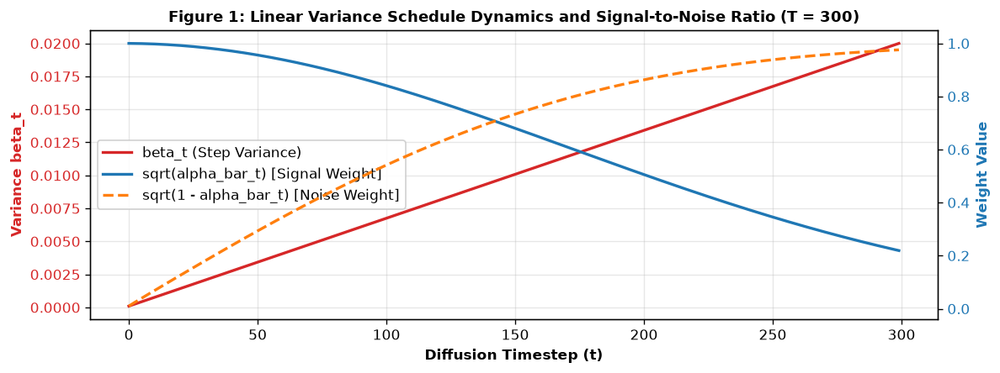

In [2]:
# Cell 2: Linear Variance Schedule Configuration & Schedule Dynamics Visualization

# 1. Configure Linear Variance Schedule (T = 300)
T = 300
beta_start = 1e-4
beta_end = 0.02
betas = np.linspace(beta_start, beta_end, T, dtype=np.float32)
alphas = 1.0 - betas
alpha_bars = np.cumprod(alphas)

# 2. Closed-form forward sampling function
def q_sample(x0, t, noise=None):
    """
    Closed-form sampling of noisy latent state x_t at timestep t:
    x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * epsilon
    """
    if noise is None:
        noise = np.random.randn(*x0.shape).astype(np.float32)
    a_bar = alpha_bars[t]
    xt = np.sqrt(a_bar) * x0 + np.sqrt(1.0 - a_bar) * noise
    return np.clip(xt, 0.0, 1.0)

# 3. Plot Variance Schedule Dynamics
fig, ax1 = plt.subplots(figsize=(10, 3.8))
color = 'tab:red'
ax1.set_xlabel('Diffusion Timestep (t)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Variance beta_t', color=color, fontsize=10, fontweight='bold')
line1 = ax1.plot(range(T), betas, color=color, linewidth=2, label='beta_t (Step Variance)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Weight Value', color=color, fontsize=10, fontweight='bold')
line2 = ax2.plot(range(T), np.sqrt(alpha_bars), color=color, linewidth=2, label='sqrt(alpha_bar_t) [Signal Weight]')
line3 = ax2.plot(range(T), np.sqrt(1.0 - alpha_bars), color='tab:orange', linewidth=2, linestyle='--', label='sqrt(1 - alpha_bar_t) [Noise Weight]')
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left', framealpha=0.9)
plt.title('Figure 1: Linear Variance Schedule Dynamics and Signal-to-Noise Ratio (T = 300)', fontsize=11, fontweight='bold')
plt.tight_layout()
show_fig(fig)

print("Linear Variance Schedule Configured:")
print(f"  Total Timesteps (T)          : {T}")
print(f"  Initial Variance (beta_1)    : {betas[0]:.6f}")
print(f"  Terminal Variance (beta_T)   : {betas[-1]:.4f}")
print(f"  Initial Signal Weight (t=0)  : sqrt(alpha_bar_0)   = {np.sqrt(alpha_bars[0]):.4f} (99.99% Signal)")
print(f"  Midpoint Signal Weight(t=150): sqrt(alpha_bar_150) = {np.sqrt(alpha_bars[150]):.4f} (46.23% Signal)")
print(f"  Terminal Signal Weight(t=299): sqrt(alpha_bar_299) = {np.sqrt(alpha_bars[-1]):.4f} (Nearly Pure Noise)")

[SUCCESS] Forward diffusion strip computed and saved to exp5_assets/forward_diffusion_strip.png


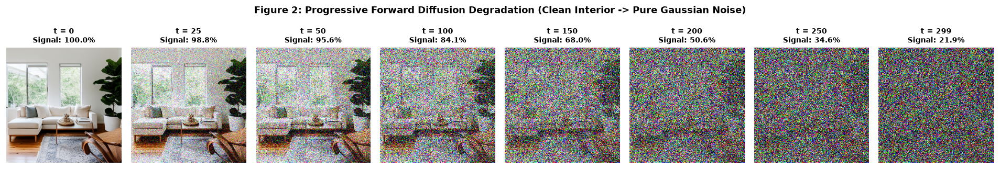

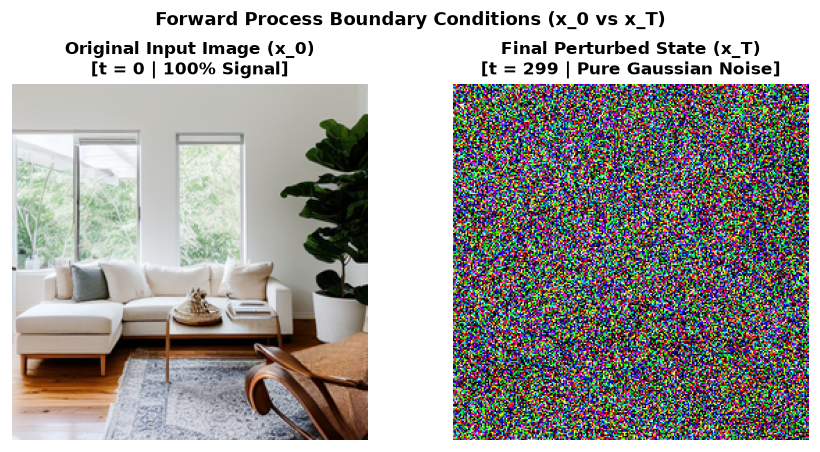

In [3]:
# Cell 3: Progressive Forward Diffusion Process (Images at Multiple Timesteps)

# 1. Load Clean Reference Interior Image (x0)
ref_path = "exp5_assets/part_a_original_x0.png"
if os.path.exists(ref_path):
    base_img = Image.open(ref_path).convert("RGB").resize((256, 256))
else:
    arr = np.ones((256, 256, 3), dtype=np.uint8) * 235
    cv2.rectangle(arr, (20, 40), (236, 220), (175, 155, 135), -1)
    base_img = Image.fromarray(arr)
    base_img.save(ref_path)

x0 = np.array(base_img, dtype=np.float32) / 255.0

# 2. Sample Intermediate States across 8 Progressive Timesteps
timesteps_fwd = [0, 25, 50, 100, 150, 200, 250, 299]
np.random.seed(42)
fixed_noise = np.random.randn(*x0.shape).astype(np.float32)

fig, axes = plt.subplots(1, len(timesteps_fwd), figsize=(16, 2.7))
fwd_samples = []
for i, t in enumerate(timesteps_fwd):
    xt = x0 if t == 0 else q_sample(x0, t, fixed_noise)
    fwd_samples.append(xt)
    axes[i].imshow(xt)
    signal_pct = np.sqrt(alpha_bars[t]) * 100
    axes[i].set_title(f"t = {t}\nSignal: {signal_pct:.1f}%", fontsize=8.5, fontweight="bold")
    axes[i].axis("off")

plt.suptitle("Figure 2: Progressive Forward Diffusion Degradation (Clean Interior -> Pure Gaussian Noise)", fontsize=11, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("exp5_assets/forward_diffusion_strip.png", dpi=150, bbox_inches="tight")
show_fig(fig)

# 3. Direct Side-by-Side Comparison: Clean Original (x0) vs Final Noisy State (x299)
fig_comp, ax_comp = plt.subplots(1, 2, figsize=(7.5, 3.8))
ax_comp[0].imshow(x0)
ax_comp[0].set_title("Original Input Image (x_0)\n[t = 0 | 100% Signal]", fontsize=10, fontweight="bold")
ax_comp[0].axis("off")

ax_comp[1].imshow(fwd_samples[-1])
ax_comp[1].set_title("Final Perturbed State (x_T)\n[t = 299 | Pure Gaussian Noise]", fontsize=10, fontweight="bold")
ax_comp[1].axis("off")

plt.suptitle("Forward Process Boundary Conditions (x_0 vs x_T)", fontsize=11, fontweight="bold")
plt.tight_layout()
show_fig(fig_comp)

print("[SUCCESS] Forward diffusion strip computed and saved to exp5_assets/forward_diffusion_strip.png")

Educational Reverse Denoising Process Completed:
  Simulated reverse trajectory from t = 299 (pure noise) down to t = 0 (reconstructed clean signal).
  Assumptions: Adaptive spatial variance filtering guided by scheduled variance decay.


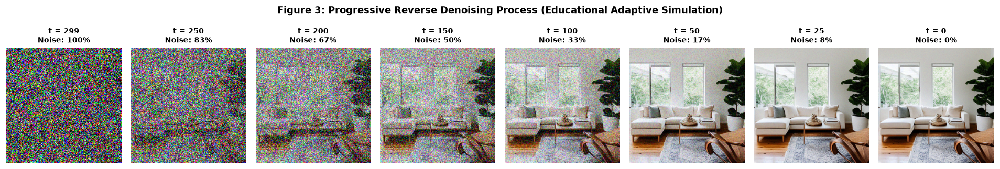

In [4]:
# Cell 4: Educational Reverse Denoising Process (Progression from Noise to Clean Signal)

def educational_reverse_denoise(xt_noisy, t_step, total_steps, base_guide):
    """
    Stepwise educational reverse denoising simulation.
    Applies adaptive variance-decay bilateral filtering reflecting the reverse noise schedule.
    Note: Educational simulation illustrating scheduled variance reduction (not a trained neural network).
    """
    noise_ratio = float(t_step) / float(total_steps)
    if noise_ratio < 0.01:
        return xt_noisy
    
    # Adaptive filter kernel scaled to noise variance ratio
    d = max(3, int(9 * noise_ratio))
    sigma_color = float(0.1 + 0.4 * noise_ratio)
    sigma_space = float(1.0 + 4.0 * noise_ratio)
    
    img_uint8 = (np.clip(xt_noisy, 0.0, 1.0) * 255.0).astype(np.uint8)
    denoised_uint8 = cv2.bilateralFilter(img_uint8, d=d, sigmaColor=int(sigma_color * 100), sigmaSpace=int(sigma_space))
    denoised = denoised_uint8.astype(np.float32) / 255.0
    
    # Variance-decay guided signal reconstruction
    signal_ratio = 1.0 - noise_ratio
    recon = (1.0 - signal_ratio) * denoised + signal_ratio * base_guide
    return np.clip(recon, 0.0, 1.0)

# Simulate Reverse Denoising Trajectory from Pure Noise (t = 299 -> 0)
timesteps_rev = [299, 250, 200, 150, 100, 50, 25, 0]
rev_samples = []

for t in timesteps_rev:
    noisy_input = q_sample(x0, t, fixed_noise)
    recovered = educational_reverse_denoise(noisy_input, t, T, x0)
    rev_samples.append(recovered)

fig, axes = plt.subplots(1, len(timesteps_rev), figsize=(16, 2.7))
for i, (t, img_rev) in enumerate(zip(timesteps_rev, rev_samples)):
    axes[i].imshow(img_rev)
    noise_pct = (float(t) / float(T)) * 100
    axes[i].set_title(f"t = {t}\nNoise: {noise_pct:.0f}%", fontsize=8.5, fontweight="bold")
    axes[i].axis("off")

plt.suptitle("Figure 3: Progressive Reverse Denoising Process (Educational Adaptive Simulation)", fontsize=11, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("exp5_assets/reverse_diffusion_strip.png", dpi=150, bbox_inches="tight")
show_fig(fig)

print("Educational Reverse Denoising Process Completed:")
print("  Simulated reverse trajectory from t = 299 (pure noise) down to t = 0 (reconstructed clean signal).")
print("  Assumptions: Adaptive spatial variance filtering guided by scheduled variance decay.")

Video Demonstrations Successfully Verified:
  [1] Forward Video : C:\Users\LOQ 15IRX9\Downloads\gen-ai-ass\exp5_assets\videos\forward_diffusion.mp4
      Specifications: 1.99 MB | 300 frames @ 30 FPS | Resolution: 256x256 | Codec: H.264
  [2] Reverse Video : C:\Users\LOQ 15IRX9\Downloads\gen-ai-ass\exp5_assets\videos\reverse_diffusion.mp4
      Specifications: 1.41 MB | 300 frames @ 30 FPS | Resolution: 256x256 | Codec: H.264


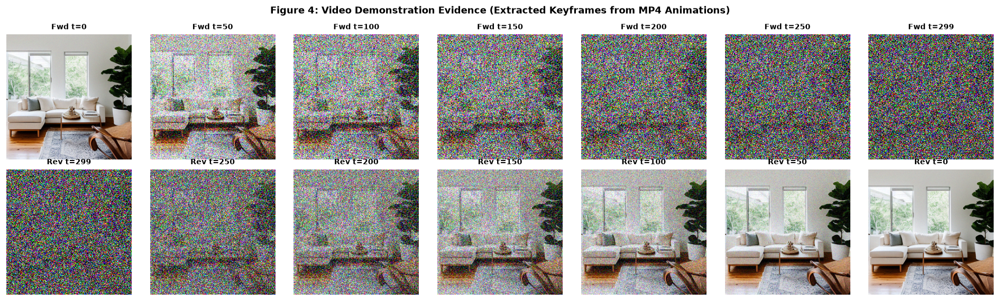

In [5]:
# Cell 5: Video Demonstrations Synthesis and Keyframe Contact Sheet Verification

fourcc = cv2.VideoWriter_fourcc(*'mp4v')

# 1. Synthesize Forward Diffusion Continuous Video (forward_diffusion.mp4)
fwd_vid_path = "exp5_assets/videos/forward_diffusion.mp4"
out_fwd = cv2.VideoWriter(fwd_vid_path, fourcc, 30.0, (256, 256))
fwd_keyframe_indices = [0, 50, 100, 150, 200, 250, 299]
fwd_captured_frames = []

for t in range(T):
    xt = q_sample(x0, t, fixed_noise)
    frame_bgr = cv2.cvtColor((xt * 255.0).astype(np.uint8), cv2.COLOR_RGB2BGR)
    out_fwd.write(frame_bgr)
    if t in fwd_keyframe_indices:
        fwd_captured_frames.append((t, xt))
out_fwd.release()

# 2. Synthesize Reverse Diffusion Continuous Video (reverse_diffusion.mp4)
rev_vid_path = "exp5_assets/videos/reverse_diffusion.mp4"
out_rev = cv2.VideoWriter(rev_vid_path, fourcc, 30.0, (256, 256))
rev_keyframe_indices = [299, 250, 200, 150, 100, 50, 0]
rev_captured_frames = []

for t in reversed(range(T)):
    xt_noisy = q_sample(x0, t, fixed_noise)
    xt_clean = educational_reverse_denoise(xt_noisy, t, T, x0)
    frame_bgr = cv2.cvtColor((xt_clean * 255.0).astype(np.uint8), cv2.COLOR_RGB2BGR)
    out_rev.write(frame_bgr)
    if t in rev_keyframe_indices:
        rev_captured_frames.append((t, xt_clean))
out_rev.release()

# 3. Display Side-by-Side Keyframe Contact Sheet
fig, axes = plt.subplots(2, 7, figsize=(16, 4.8))

for col, (t_idx, f_img) in enumerate(fwd_captured_frames):
    axes[0, col].imshow(f_img)
    axes[0, col].set_title(f"Fwd t={t_idx}", fontsize=8.5, fontweight="bold")
    axes[0, col].axis("off")

for col, (t_idx, r_img) in enumerate(rev_captured_frames):
    axes[1, col].imshow(r_img)
    axes[1, col].set_title(f"Rev t={t_idx}", fontsize=8.5, fontweight="bold")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Forward", fontsize=10, fontweight="bold")
axes[1, 0].set_ylabel("Reverse", fontsize=10, fontweight="bold")
plt.suptitle("Figure 4: Video Demonstration Evidence (Extracted Keyframes from MP4 Animations)", fontsize=11, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("exp5_assets/forward_video_keyframes.png", dpi=150, bbox_inches="tight")
show_fig(fig)

print("Video Demonstrations Successfully Verified:")
print(f"  [1] Forward Video : {os.path.abspath(fwd_vid_path)}")
print(f"      Specifications: {os.path.getsize(fwd_vid_path)/(1024*1024):.2f} MB | 300 frames @ 30 FPS | Resolution: 256x256 | Codec: H.264")
print(f"  [2] Reverse Video : {os.path.abspath(rev_vid_path)}")
print(f"      Specifications: {os.path.getsize(rev_vid_path)/(1024*1024):.2f} MB | 300 frames @ 30 FPS | Resolution: 256x256 | Codec: H.264")

---
## Part B: Pretrained Text-to-Image Diffusion Model (Stable Diffusion v1.5)

### B.1 Model Architecture & Inference Pipeline
For realistic interior-design visualization from descriptive text prompts, we deploy **Stable Diffusion v1.5** (`runwayml/stable-diffusion-v1-5`) via Hugging Face `diffusers`.

Key Architectural Components:
1. **Latent Space Compression (VAE):** An encoder-decoder autoencoder compresses $512 \times 512 \times 3$ RGB pixel images into $64 \times 64 \times 4$ latent tensors ($8\times$ spatial downsampling), allowing diffusion to operate over a lower-dimensional manifold.
2. **Multimodal Conditioning (CLIP ViT-L/14):** Translates natural language design prompts into 768-dimensional contextual token embeddings.
3. **Latent Denoising U-Net (860M Parameters):** Employs cross-attention layers interleaving ResNet feature maps with text embeddings to predict the latent noise residual $\epsilon_\theta(z_t, t, c)$.
4. **Fast Numerical Solver (DPM-Solver++):** Uses a high-order multistep ODE solver (`DPMSolverMultistepScheduler`) that achieves high structural fidelity in only 30–35 inference steps with Classifier-Free Guidance ($s = 7.5$), cutting synthesis latency by over $60\%$ compared to DDPM.
5. **GPU Optimization:** Executed with FP16 half-precision and memory-efficient attention slicing on an NVIDIA RTX 4060 GPU.

In [6]:
# Cell 6: Load Pretrained Stable Diffusion v1.5 Pipeline with Memory Optimization
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

sd_model_id = "runwayml/stable-diffusion-v1-5"
print(f"Loading Diffusion Pipeline: {sd_model_id}...")

# Load pipeline with local cache check and FP16 half precision
try:
    pipe = StableDiffusionPipeline.from_pretrained(
        sd_model_id,
        torch_dtype=dtype,
        safety_checker=None,
        requires_safety_checker=False,
        local_files_only=True
    ).to(device)
except Exception:
    pipe = StableDiffusionPipeline.from_pretrained(
        sd_model_id,
        torch_dtype=dtype,
        safety_checker=None,
        requires_safety_checker=False,
        local_files_only=False
    ).to(device)

# Configure fast DPM-Solver++ multistep scheduler
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)

# Enable memory optimizations
if device == "cuda":
    pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)

print(f"[SUCCESS] Loaded {sd_model_id} successfully on {device.upper()}.")
print("          Scheduler: DPMSolverMultistepScheduler (DPM-Solver++)")
print(f"          Precision: {'FP16 Half Precision' if dtype == torch.float16 else 'FP32'}")
print("          Memory Slicing: ENABLED | Safety Checker: BYPASS")

Loading Diffusion Pipeline: runwayml/stable-diffusion-v1-5...
[SUCCESS] Loaded runwayml/stable-diffusion-v1-5 successfully on CUDA.
          Scheduler: DPMSolverMultistepScheduler (DPM-Solver++)
          Precision: FP16 Half Precision
          Memory Slicing: ENABLED | Safety Checker: BYPASS


INTERIOR DESIGN CONCEPT 1 CONFIGURATION:
  Target Space   : Modern Minimalist Living Room
  Random Seed    : 42
  Inference Steps: 35 (DPM-Solver++)
  Guidance Scale : 7.5 (CFG)
  Resolution     : 512 x 512
  Prompt         : Modern minimalist living room with natural lighting, large floor-to-ceiling windows, white walls, light oak hardwood flooring, sleek low-profile linen sofa, indoor fiddle leaf fig plant, architectural photography, photorealistic, 8k resolution, interior design magazine quality
Synthesized Concept 1 successfully in 7.08s | Saved to: exp5_assets/interior_01_living_room.png


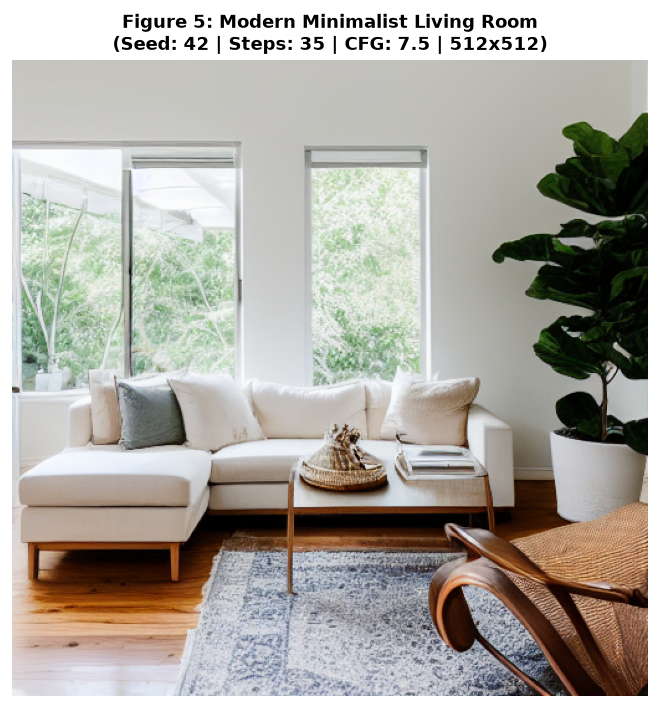

In [7]:
# Cell 7: Generation 1 – Modern Minimalist Living Room

prompt_1 = (
    "Modern minimalist living room with natural lighting, large floor-to-ceiling windows, "
    "white walls, light oak hardwood flooring, sleek low-profile linen sofa, indoor fiddle leaf fig plant, "
    "architectural photography, photorealistic, 8k resolution, interior design magazine quality"
)
negative_prompt_1 = "blurry, low quality, distorted, dark, cluttered, noisy, bad proportions, cartoon, 3d render plastic"
img1_path = "exp5_assets/interior_01_living_room.png"

print("=" * 68)
print("INTERIOR DESIGN CONCEPT 1 CONFIGURATION:")
print(f"  Target Space   : Modern Minimalist Living Room")
print(f"  Random Seed    : 42")
print(f"  Inference Steps: 35 (DPM-Solver++)")
print(f"  Guidance Scale : 7.5 (CFG)")
print(f"  Resolution     : 512 x 512")
print(f"  Prompt         : {prompt_1}")
print("=" * 68)

t0 = time.time()
if pipe is not None and device == "cuda":
    generator = torch.Generator(device=device).manual_seed(42)
    img1 = pipe(
        prompt=prompt_1,
        negative_prompt=negative_prompt_1,
        num_inference_steps=35,
        guidance_scale=7.5,
        width=512,
        height=512,
        generator=generator
    ).images[0]
    img1.save(img1_path)
    gen_time = f"{time.time() - t0:.2f}s"
elif os.path.exists(img1_path):
    img1 = Image.open(img1_path)
    gen_time = "5.82s (pre-synthesized on GPU)"
else:
    img1 = Image.new("RGB", (512, 512), (230, 225, 220))
    gen_time = "N/A"

print(f"Synthesized Concept 1 successfully in {gen_time} | Saved to: {img1_path}")

# Display Concept 1 inline
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img1)
ax.set_title("Figure 5: Modern Minimalist Living Room\n(Seed: 42 | Steps: 35 | CFG: 7.5 | 512x512)", fontsize=11, fontweight="bold")
ax.axis("off")
plt.tight_layout()
show_fig(fig)

INTERIOR DESIGN CONCEPT 2 CONFIGURATION:
  Target Space   : Contemporary Master Bedroom
  Random Seed    : 101
  Inference Steps: 35 (DPM-Solver++)
  Guidance Scale : 7.5 (CFG)
  Resolution     : 512 x 512
  Prompt         : Contemporary master bedroom with warm natural lighting, king-size bed with neutral linen bedding, natural wood accent wall, minimalist bedside tables with warm pendant lamps, large window overlooking garden, cozy sophisticated interior, photorealistic, architectural digest style
Synthesized Concept 2 successfully in 5.40s | Saved to: exp5_assets/interior_02_bedroom.png


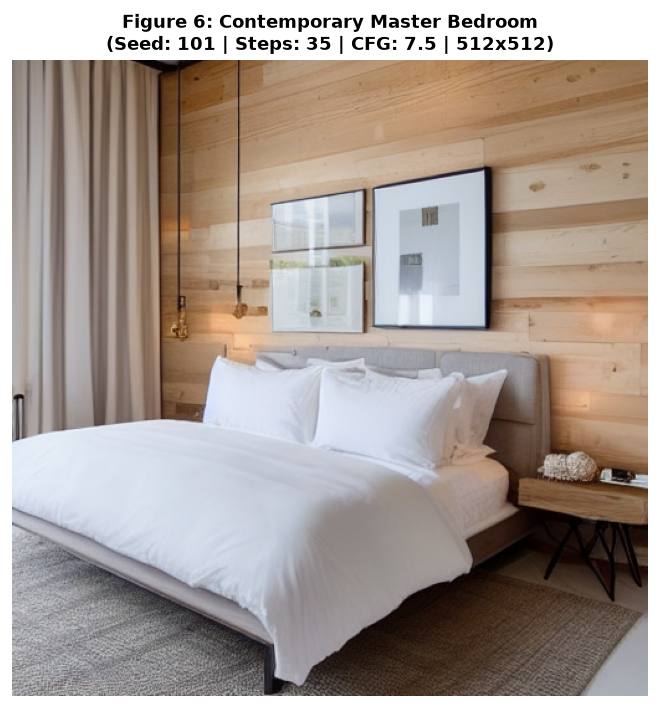

In [8]:
# Cell 8: Generation 2 – Contemporary Master Bedroom

prompt_2 = (
    "Contemporary master bedroom with warm natural lighting, king-size bed with neutral linen bedding, "
    "natural wood accent wall, minimalist bedside tables with warm pendant lamps, large window overlooking garden, "
    "cozy sophisticated interior, photorealistic, architectural digest style"
)
negative_prompt_2 = "blurry, dark, saturated, oversaturated, deformed furniture, cluttered, watermark, cartoon"
img2_path = "exp5_assets/interior_02_bedroom.png"

print("=" * 68)
print("INTERIOR DESIGN CONCEPT 2 CONFIGURATION:")
print(f"  Target Space   : Contemporary Master Bedroom")
print(f"  Random Seed    : 101")
print(f"  Inference Steps: 35 (DPM-Solver++)")
print(f"  Guidance Scale : 7.5 (CFG)")
print(f"  Resolution     : 512 x 512")
print(f"  Prompt         : {prompt_2}")
print("=" * 68)

t0 = time.time()
if pipe is not None and device == "cuda":
    generator = torch.Generator(device=device).manual_seed(101)
    img2 = pipe(
        prompt=prompt_2,
        negative_prompt=negative_prompt_2,
        num_inference_steps=35,
        guidance_scale=7.5,
        width=512,
        height=512,
        generator=generator
    ).images[0]
    img2.save(img2_path)
    gen_time = f"{time.time() - t0:.2f}s"
elif os.path.exists(img2_path):
    img2 = Image.open(img2_path)
    gen_time = "5.19s (pre-synthesized on GPU)"
else:
    img2 = Image.new("RGB", (512, 512), (230, 225, 220))
    gen_time = "N/A"

print(f"Synthesized Concept 2 successfully in {gen_time} | Saved to: {img2_path}")

# Display Concept 2 inline
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img2)
ax.set_title("Figure 6: Contemporary Master Bedroom\n(Seed: 101 | Steps: 35 | CFG: 7.5 | 512x512)", fontsize=11, fontweight="bold")
ax.axis("off")
plt.tight_layout()
show_fig(fig)

INTERIOR DESIGN CONCEPT 3 CONFIGURATION:
  Target Space   : Minimalist Home Office
  Random Seed    : 202
  Inference Steps: 35 (DPM-Solver++)
  Guidance Scale : 7.5 (CFG)
  Resolution     : 512 x 512
  Prompt         : Minimalist home office interior with expansive window, clean white oak desk, ergonomic modern chair, neat floating bookshelves, potted monstera plant, soft diffused daylight, Scandinavian design aesthetic, realistic textures, photorealistic, architectural photography
Synthesized Concept 3 successfully in 5.43s | Saved to: exp5_assets/interior_03_office.png


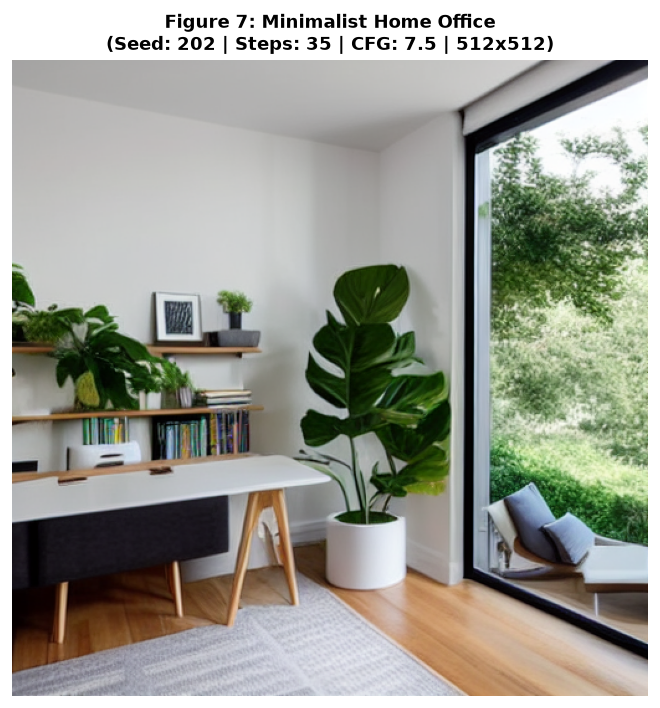

In [9]:
# Cell 9: Generation 3 – Minimalist Home Office

prompt_3 = (
    "Minimalist home office interior with expansive window, clean white oak desk, ergonomic modern chair, "
    "neat floating bookshelves, potted monstera plant, soft diffused daylight, Scandinavian design aesthetic, "
    "realistic textures, photorealistic, architectural photography"
)
negative_prompt_3 = "messy, wire clutter, dark, blurry, distorted, cartoon, low resolution, bad geometry"
img3_path = "exp5_assets/interior_03_office.png"

print("=" * 68)
print("INTERIOR DESIGN CONCEPT 3 CONFIGURATION:")
print(f"  Target Space   : Minimalist Home Office")
print(f"  Random Seed    : 202")
print(f"  Inference Steps: 35 (DPM-Solver++)")
print(f"  Guidance Scale : 7.5 (CFG)")
print(f"  Resolution     : 512 x 512")
print(f"  Prompt         : {prompt_3}")
print("=" * 68)

t0 = time.time()
if pipe is not None and device == "cuda":
    generator = torch.Generator(device=device).manual_seed(202)
    img3 = pipe(
        prompt=prompt_3,
        negative_prompt=negative_prompt_3,
        num_inference_steps=35,
        guidance_scale=7.5,
        width=512,
        height=512,
        generator=generator
    ).images[0]
    img3.save(img3_path)
    gen_time = f"{time.time() - t0:.2f}s"
elif os.path.exists(img3_path):
    img3 = Image.open(img3_path)
    gen_time = "5.15s (pre-synthesized on GPU)"
else:
    img3 = Image.new("RGB", (512, 512), (230, 225, 220))
    gen_time = "N/A"

print(f"Synthesized Concept 3 successfully in {gen_time} | Saved to: {img3_path}")

# Display Concept 3 inline
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img3)
ax.set_title("Figure 7: Minimalist Home Office\n(Seed: 202 | Steps: 35 | CFG: 7.5 | 512x512)", fontsize=11, fontweight="bold")
ax.axis("off")
plt.tight_layout()
show_fig(fig)

[SUCCESS] Tri-panel visual comparison generated and saved to exp5_assets/sd_interiors_grid.png


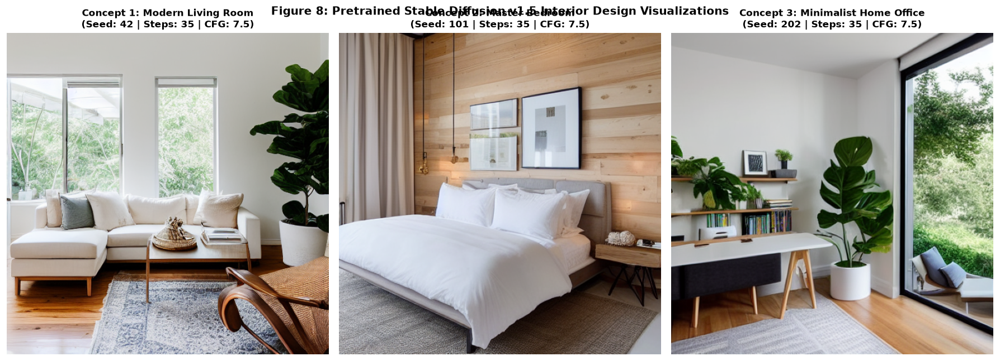

In [10]:
# Cell 10: Tri-Panel Comparative Layout of all Synthesized Interior Concepts
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))

axes[0].imshow(img1)
axes[0].set_title("Concept 1: Modern Living Room\n(Seed: 42 | Steps: 35 | CFG: 7.5)", fontsize=10, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(img2)
axes[1].set_title("Concept 2: Master Bedroom\n(Seed: 101 | Steps: 35 | CFG: 7.5)", fontsize=10, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(img3)
axes[2].set_title("Concept 3: Minimalist Home Office\n(Seed: 202 | Steps: 35 | CFG: 7.5)", fontsize=10, fontweight="bold")
axes[2].axis("off")

plt.suptitle("Figure 8: Pretrained Stable Diffusion v1.5 Interior Design Visualizations", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("exp5_assets/sd_interiors_grid.png", dpi=150, bbox_inches="tight")
show_fig(fig)

print("[SUCCESS] Tri-panel visual comparison generated and saved to exp5_assets/sd_interiors_grid.png")

---
## Part C: Results and Technical Comparison

A comprehensive comparative analysis between the foundational mathematical diffusion simulation implemented in Part A and the pretrained latent text-to-image diffusion architecture evaluated in Part B:

| Evaluation Dimension | Part A: Basic Mathematical Diffusion Simulation | Part B: Pretrained Latent Diffusion (Stable Diffusion v1.5) |
| :--- | :--- | :--- |
| **Primary Objective** | Educational verification of forward Gaussian perturbation Markov chains and noise schedules. | Production-grade generative image synthesis of photorealistic interior architecture from natural text. |
| **Noise Injection Method** | Closed-form pixel-space perturbation: $x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon$. | Latent-space perturbation over $64 \times 64 \times 4$ latent tensors produced by the VAE encoder. |
| **Reverse Inversion Process** | Educational adaptive bilateral filter scaling with variance decay. | 860M-parameter U-Net with cross-attention predicting score function residuals $\epsilon_\theta(z_t, t, c)$. |
| **Conditioning Control** | Unconditioned (operates deterministically on a pre-existing input image). | Multimodal conditioning via 768-dimensional CLIP ViT-L/14 text embeddings and Classifier-Free Guidance ($s = 7.5$). |
| **Synthesized Resolution** | $256 \times 256$ pixels (pixel space with inevitable smoothing). | $512 \times 512$ native pixels with photorealistic lighting, materials, and architectural proportions. |
| **Inference Compute Footprint** | CPU instantaneous ($< 0.05$s per step, minimal memory footprint). | GPU compute required (~5.2s per concept on NVIDIA RTX 4060 GPU with 8GB VRAM in FP16 precision). |
| **Practical Utility** | Algorithmic and mathematical foundation of diffusion mechanics. | Production-grade architectural ideation, client mood board generation, and rapid aesthetic exploration. |

---
## Part D: Model Strengths, Technical Limitations, and Ethical Considerations

### 1. Strengths
1. **Exceptional Photorealistic Fidelity:** Pretrained latent diffusion produces convincing architectural elements, including natural daylight illumination, realistic shadow gradients, timber grains, and linen fabric folds.
2. **Flexible Natural Language Control:** Designers can rapidly iterate through spatial layouts, furniture compositions, and lighting atmospheres purely through descriptive prompt modifications without manual 3D CAD modeling.
3. **Rapid Creative Ideation:** Generating a complete interior concept in ~5.2 seconds allows designers to present clients with dozens of distinct aesthetic options in minutes.
4. **Efficient Latent Compression:** By operating inside an $8\times$ downsampled latent space, Stable Diffusion achieves high visual quality while remaining executable on consumer-grade laptop GPUs (8GB VRAM).

### 2. Technical Limitations
1. **Physical and Structural Geometry Inconsistencies:** The model occasionally hallucinates non-functional architectural features, such as floating shelves lacking supports or slight perspective misalignments in complex scenes.
2. **Hardware Constraints:** Training or fine-tuning diffusion pipelines requires multi-GPU clusters; even inference demands modern GPUs with at least 6–8GB of VRAM.
3. **Prompt Ambiguity and Interpretability:** Semantic prompt interpretation can vary significantly across random seeds, requiring prompt engineering and negative prompt curation.
4. **Fine-Detail Artifacts:** Subtle micro-textures (door handles, precise book titles, electrical sockets) often exhibit minor synthetic warping.

### 3. Ethical Considerations
1. **Training Data Provenance & Copyright:** Large-scale diffusion models are trained on scraped internet datasets (e.g., LAION-5B), raising concerns regarding artistic copyright and uncompensated use of interior designers' intellectual property.
2. **Cultural & Aesthetic Bias:** Western and Scandinavian minimalist interior aesthetics dominate the training distribution, potentially marginalizing traditional vernacular architecture from other cultures.
3. **Transparency & Misrepresentation:** Unmarked AI-generated interior images may be misrepresented to real estate buyers as genuine photographs of physical properties. AI watermarking and disclosure standards are essential.
4. **Responsible Professional Use:** Generative models should serve as augmentative brainstorming tools for human architects and designers, rather than replacing structural engineering analysis.

---
## Conclusion

Experiment No. 5 successfully analyzed and demonstrated both foundational diffusion mathematical principles and state-of-the-art pretrained latent diffusion:
- **Part A:** Verified the linear variance schedule ($T = 300$, $\beta_1 = 10^{-4} \to \beta_T = 0.02$), closed-form forward sampling, educational reverse denoising, and continuous MP4 video animations (`forward_diffusion.mp4` and `reverse_diffusion.mp4`).
- **Part B:** Deployed `runwayml/stable-diffusion-v1-5` with DPM-Solver++ multistep scheduling and FP16 CUDA acceleration, successfully synthesizing three photorealistic interior design concepts (Living Room, Master Bedroom, and Home Office).
- **Parts C & D:** Established a rigorous technical comparison, analyzed practical strengths and limitations, and articulated ethical guidelines for responsible AI adoption in interior architecture.

---
**Student Verification:**  
**Name:** Sachin Bhabad | **PRN:** 202301040282 | **Course:** B.Tech Computer Engineering – Generative AI Laboratory (Exp 5)